<a href="https://colab.research.google.com/github/fernanda592/CLASE-2/blob/main/Sesion5_Actividad_Aplicacion_del_Proceso_Edith_Fernanda_Pachon_Sisa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EDA**

1.*LIMPIEZA DE DATOS*

In [1]:
import pandas as pd
import numpy as np

In [4]:
df

,id,ciudad,edad,ingresos,compras
0,1,bogota,49.0,2952000.0,10.0
1,2,cali,50.0,7286000.0,9.0
2,3,Cali,50.0,3592000.0,5.0
3,4,Bogotá,56.0,2349000.0,9.0
4,5,bogota,55.0,3999000.0,2.0
...,...,...,...,...,...
298,299,Medellín,42.0,2234000.0,8.0
299,300,Cali,60.0,NaN,4.0
300,2,cali,50.0,7286000.0,9.0
301,3,Cali,50.0,3592000.0,5.0


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        306 non-null    int64  
 1   ciudad    306 non-null    object 
 2   edad      256 non-null    float64
 3   ingresos  291 non-null    float64
 4   compras   306 non-null    float64
 5   ingreso   2 non-null      float64
dtypes: float64(4), int64(1), object(1)
memory usage: 14.5+ KB


In [3]:
df.loc[np.random.choice(n, 25, replace=False), "edad"] = np.nan
df.loc[np.random.choice(n, 15, replace=False), "ingresos"] = np.nan
df.loc[[5, 30], "edad"] = [250, -3]
df.loc[[12, 140], "ingresos"] = [9.5e9, 4.1e9]

df = pd.concat([df, df.iloc[[1, 2, 3]]], ignore_index=True)

print(df.shape)

(303, 5)


In [7]:
# Perfilamiento de la calidad de datos
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "%nulos": (df.isna().mean() * 100).round(1),
    "únicos": df.nunique()
})

print(perfil)
print("Duplicados:", df.duplicated().sum())
print("Ciudades:", sorted(df["ciudad"].unique()))

             tipo  nulos  %nulos  únicos
id          int64      0     0.0     300
ciudad     object      0     0.0       6
edad      float64     25     8.3      54
ingresos  float64     15     5.0     280
compras   float64      0     0.0      13
Duplicados: 3
Ciudades: ['BOGOTÁ', 'Bogotá', 'Cali', 'Medellín', 'bogota', 'cali']


In [6]:
limpio = df.drop_duplicates().copy()

limpio["ciudad"] = (
    limpio["ciudad"].str.strip().str.lower()
    .str.replace("á", "a").str.replace("í", "i")
)

mapa = {"bogota": "Bogotá", "medellin": "Medellín", "cali": "Cali"}
limpio["ciudad"] = limpio["ciudad"].map(mapa)

print("Filas:", len(df), "->", len(limpio))
print(limpio["ciudad"].value_counts())

Filas: 303 -> 300
ciudad
Bogotá      157
Cali         98
Medellín     45
Name: count, dtype: int64


In [8]:
limpio.loc[(limpio["edad"] < 18) | (limpio["edad"] > 100), "edad"] = np.nan

q1, q3 = limpio["ingresos"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr

atipicos = limpio[
    (limpio["ingresos"] < lim_inf) |
    (limpio["ingresos"] > lim_sup)
]

print(f"Límite superior: {lim_sup:,.0f}")
print("Atípicos:", len(atipicos))
print(atipicos["ingresos"].sort_values().tail(3).tolist())

Límite superior: 7,139,000
Atípicos: 9
[8196000.0, 4100000000.0, 9500000000.0]


In [15]:
df.loc[np.random.choice(n, 25, replace=False), "edad"] = np.nan
df.loc[np.random.choice(n, 15, replace=False), "ingreso"] = np.nan
df.loc[[5, 80], "edad"] = [250, -3]
df.loc[[12, 140], "ingreso"] = [9.5e9, 4.1e9]
df = pd.concat([df, df.iloc[[1, 2, 3]]], ignore_index=True)
print(df.shape)

(306, 6)


In [11]:
limpio["rango_edad"] = pd.cut(
    limpio["edad"],
    bins=[17, 30, 45, 60, 100],
    labels=["18-30", "31-45", "46-60", "60+"])

tabla = limpio.groupby("rango_edad", observed=True).agg(
    clientes=("id", "count"),
    ingreso_med=("ingresos", "median"),
    compras_prom=("compras", "mean")).round(1)

print(tabla)
print("Correlación ingreso-compras:", round(limpio["ingresos"].corr(limpio["compras"]), 2))

            clientes  ingreso_med  compras_prom
rango_edad                                     
18-30             62    3572500.0           5.9
31-45             88    3372000.0           5.6
46-60             83    3000000.0           5.8
60+               40    2618000.0           5.6
Correlación ingreso-compras: 0.11


KeyError: 'ingreso'

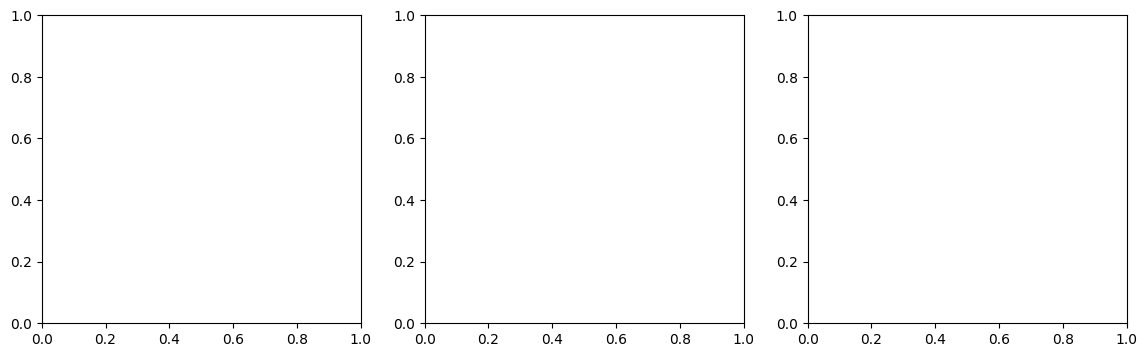

In [18]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
limpio["ingreso"].div(1e6).plot.hist(bins=25, ax=ax[0],

                                     title="Ingreso (M)")

limpio.boxplot(column="edad", by="ciudad", ax=ax[1])

limpio.plot.scatter(x="ingreso", y="compras", ax=ax[2], alpha=.5)

plt.tight_layout()